# 18b · Two bounds: better member with literature harm, deployed model with every miss blinding (secondary, post hoc)

**Status: secondary and post hoc**, a companion to notebook 18. It reads the same frozen v2 predictions, uses the same 33 EyePACS-trained models, 55 pairs × 9 seed combinations, bootstrap and rank rule, and writes a separate results file. It changes nothing in notebook 18 or in any lock.

**Why two comparators.** Notebook 18 compared each pair with its *better* member, chosen with hindsight in each resample. A programme cannot know in advance which of two models is better on its own population. What it actually deploys is one of them. So there are two honest comparators:
- **Better member.** The pair must beat whichever model turns out best. This is the hardest test for pairing.
- **Deployed model.** The pair is compared with a model chosen without knowing which is better, averaged over both choices (each member equally likely). This is the comparator in the BRSET lock v6.

**Why two harm models.**
- **Literature harm.** The notebook 18 values: a missed PDR eye goes blind with probability 0.0475, severe NPDR 0.0056, moderate NPDR 0.00095.
- **Every missed severe eye blinds.** Each missed grade 3 or 4 eye counts as one blind eye. Missed grade 2 eyes keep the literature high value (0.003). This is the clinical tail-risk view: treat every serious miss as if it will cost the eye.

**The two bounds.**

| Bound | Comparator | Harm | What it answers |
|---|---|---|---|
| Mathematically conservative | Better member | Literature | Does pairing pay even against the best single model, with harm at its expected value? |
| Clinically conservative | Deployed model | Every missed severe eye blinds | Does pairing pay for the patient when you cannot pick the better model in advance, and a missed severe eye is treated as a lost eye? |

All four combinations are also reported, so either axis can be read alone.

**Pricing.** As in notebook 18, K is the number of false referrals a programme accepts to prevent one blind eye, now swept from 10 to 100,000. In QALYs, under the only-eye valuation (3.21 QALY per blind eye, one visit 0.001 to 0.004 QALY), one visit corresponds to K of about 800 to 3,200.

**Runtime:** CPU, high-RAM, about 1 to 2 hours. Only aggregate numbers leave the runtime.

In [1]:
# --- setup ---
from google.colab import drive
drive.mount("/content/drive")
import os, re, json, hashlib, itertools, datetime, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
BASE = "/content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2"
PREDS, SPLITS, RESULTS, FIGS = (f"{BASE}/{d}" for d in ("03_predictions", "01_splits", "04_results", "05_figures"))
BRSET_LABELS = "/content/drive/MyDrive/stochastic_orthogonality/data/brset/label_brset.csv"
OUT_JSON = f"{RESULTS}/literature_weighted_bounds_v2.json"
assert not os.path.exists(OUT_JSON), "this secondary analysis has already been written; rename the old output deliberately to rerun"
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
ARCHS = ["densenet121_binary", "densenet121_5class", "efficientnet_b3_binary", "efficientnet_b3_5class", "resnet50_binary", "resnet50_5class",
         "vit_base_binary", "vit_base_5class", "retfound_binary", "retfound_5class", "retfound_adversarial"]
SEEDS = [0, 1, 2]; PAIRS = list(itertools.combinations(ARCHS, 2))
def tag(k): return "" if k == 0 else f"_seed{k}"
MODELS = [(a, k) for a in ARCHS for k in SEEDS]
B, SEED = 1000, 20261028
VOLS = np.round(np.arange(0.01, 0.701, 0.01), 2)

# harm model (severe visual loss events per missed eye, one-year delay)
PDR = {"low": 0.02, "central": 0.0475, "high": 0.075}
P_HR_G3, DIRECT_G3 = 0.15, 0.002
P_PDR_G2 = {"low": 0.02, "central": 0.04, "high": 0.08}
SY = {"low": 10, "central": 15, "high": 20}; QALY_PER_BLIND_YEAR = 0.214
def svl(grade, sc):
    r = PDR[sc]
    return np.select([grade == 4, grade == 3, grade == 2], [r, P_HR_G3 * 0.5 * r + DIRECT_G3, P_PDR_G2[sc] * 0.5 * r], 0.0)
KS = np.round(np.geomspace(10, 100000, 41), 1)          # false referrals one prevented severe visual loss event is worth
LAMBDAS = np.round(np.geomspace(1e-4, 3e-2, 25), 6); BAND = (0.001, 0.004); LAM_ANCHOR = 0.0025
NPJ_GRID = {"miss": [[500, 200, 15], [250, 100, 10], [1000, 400, 20], [100, 50, 10], [50, 25, 5]], "wfp": [1, 5, 20, 50, 100]}
for sc in ("low", "central", "high"):
    print(f"{sc:>7}: per missed eye, severe visual loss events  g4 {svl(np.array(4), sc):.4f}  g3 {svl(np.array(3), sc):.4f}  g2 {svl(np.array(2), sc):.5f}"
          f"  | QALY per event {SY[sc] * QALY_PER_BLIND_YEAR:.2f}")

Mounted at /content/drive
    low: per missed eye, severe visual loss events  g4 0.0200  g3 0.0035  g2 0.00020  | QALY per event 2.14
central: per missed eye, severe visual loss events  g4 0.0475  g3 0.0056  g2 0.00095  | QALY per event 3.21
   high: per missed eye, severe visual loss events  g4 0.0750  g3 0.0076  g2 0.00300  | QALY per event 4.28


## 1. Load the three populations (frozen predictions only)

In [2]:
def pick(cols, pats, what):
    m = [c for c in cols if any(re.fullmatch(p, c, flags=re.I) for p in pats)]
    assert len(m) == 1, f"cannot identify the {what} column; columns are {list(cols)}"
    return m[0]
F_OVERRIDE = {}   # e.g. {"ddr": 0.56} if the printed f differs from the locked value
def norm(x): return pd.Series(x, dtype=str).str.replace(r"\.(jpe?g|png|tiff?)$", "", regex=True, flags=re.I).to_numpy()
HASHES = {}
def load_preds(fmt, key="image_id"):
    P = {}; ref = None
    for a, k in MODELS:
        fn = f"{PREDS}/{fmt.format(arch=a, tag=tag(k))}"; HASHES[os.path.basename(fn)] = sha256_file(fn)
        d = pd.read_csv(fn, dtype={key: str})
        if ref is None: ref = d
        else: assert (d[key].values == ref[key].values).all(), f"row order differs in {os.path.basename(fn)}"
        P[(a, k)] = d["predicted_probability"].to_numpy(np.float64)
    return ref, P
POP = {}
# EyePACS fresh set (labels and patients travel with the prediction files)
ref, P = load_preds("eyepacs_predictions_fresh_{arch}{tag}_v2.csv")
POP["eyepacs"] = {"grade": ref.true_grade.to_numpy(int), "group": ref.patient_id.astype(str).to_numpy(), "P": P, "f": 0.25}
# DDR (labels and filename groups from the intraset split written before inference)
ref, P = load_preds("ddr_predictions_{arch}{tag}_v2.csv")
sp = pd.read_csv(f"{SPLITS}/ddr_split_intraset_v2.csv", dtype={"image_id": str})
gcol, grpcol = pick(sp.columns, ["grade", "true_grade", "dr_grade", "level"], "DDR grade"), pick(sp.columns, ["group", "filename_group", "group_id"], "DDR group")
sp["_k"] = norm(sp["image_id"]); sp = sp.set_index("_k").loc[norm(ref.image_id)]
half = [c for c in sp.columns if re.fullmatch("half|split|subset", c, flags=re.I)]
g = sp[gcol].to_numpy(int); keep = g <= 4
if half:
    isA = sp[half[0]].astype(str).str.strip().str.upper().isin(["A", "HALF_A", "HALFA", "0"]).to_numpy()
    print("DDR half column:", half[0], "| values:", sorted(sp[half[0]].astype(str).unique())[:6], "| treated as half A:", int((isA & keep).sum()), "eyes")
else:
    isA = np.ones(len(g), bool); print("WARNING: no DDR half column found; f uses the whole DDR prevalence")
prevA = float((g[keep & isA] >= 2).mean())
POP["ddr"] = {"grade": g[keep], "group": sp[grpcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}, "f": round(1.31 * prevA, 4)}
# BRSET (labels read from the BRSET label file; only aggregates leave this runtime)
ref, P = load_preds("brset_predictions_eyepacs_{arch}{tag}_v2.csv")
lb = pd.read_csv(BRSET_LABELS, dtype=str)
icol, pcol, idcol = pick(lb.columns, [r".*icdr.*"], "BRSET ICDR grade"), pick(lb.columns, ["patient_id", "patient"], "BRSET patient"), pick(lb.columns, ["image_id", "image"], "BRSET image id")
lb["_k"] = norm(lb[idcol]); lb = lb.set_index("_k").loc[norm(ref.image_id)]
g = pd.to_numeric(lb[icol], errors="coerce").to_numpy(); keep = np.isin(g, [0, 1, 2, 3, 4])
POP["brset"] = {"grade": g[keep].astype(int), "group": lb[pcol].astype(str).to_numpy()[keep], "P": {m: v[keep] for m, v in P.items()}}
POP["brset"]["f"] = round(1.31 * float((POP["brset"]["grade"] >= 2).mean()), 4)
for name, v in F_OVERRIDE.items(): POP[name]["f"] = v
for name, d in POP.items():
    gr = d["grade"]
    print(f"{name:>8}: {len(gr):,} eyes | {len(set(d['group'])):,} groups | referable {np.mean(gr >= 2):.3f} | grade 3 {int((gr == 3).sum())} | grade 4 {int((gr == 4).sum())} | f = {d['f']}")
print("expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075")

DDR half column: half | values: ['A', 'B'] | treated as half A: 6205 eyes
 eyepacs: 15,794 eyes | 7,897 groups | referable 0.195 | grade 3 384 | grade 4 328 | f = 0.25
     ddr: 12,422 eyes | 332 groups | referable 0.453 | grade 3 236 | grade 4 913 | f = 0.555
   brset: 16,266 eyes | 8,524 groups | referable 0.057 | grade 3 78 | grade 4 396 | f = 0.0745
expected f from the manuscript: DDR about 0.56 (from half A), BRSET about 0.075


## 2. Core computation
Same method as notebook 18, with only the contributions this notebook needs.

In [3]:
HARMS = {"lit_central": "literature harm (central)", "lit_low": "literature harm (low)", "lit_high": "literature harm (high)", "allblind": "every missed severe eye blinds"}
def setup(d):
    gr = d["grade"]; n = len(gr)
    codes = pd.factorize(d["group"])[0]; G = codes.max() + 1
    rng = np.random.default_rng(SEED)
    W = np.empty((B + 1, n), np.float32); W[0] = 1.0
    for b in range(1, B + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    contrib = {"severe_count": (gr >= 3).astype(float), "fp": (gr <= 1).astype(float)}
    for sc in ("central", "low", "high"): contrib[f"lit_{sc}"] = svl(gr, sc)
    contrib["allblind"] = np.select([gr >= 3, gr == 2], [1.0, svl(np.array(2), "high")], 0.0)
    R = {m: rankdata(p) / n for m, p in d["P"].items()}
    return {"n": n, "W": W, "Wtot": W.sum(1, dtype=np.float64), "contrib": contrib, "R": R}
def curves(S, score, vols):
    o = np.argsort(-score, kind="stable"); Wo = S["W"][:, o]; cw = np.cumsum(Wo, 1, dtype=np.float64)
    pos = np.empty((B + 1, len(vols)), np.int64)
    for b in range(B + 1): pos[b] = np.searchsorted(cw[b], vols * S["Wtot"][b], side="right")
    out = {}
    for k, c in S["contrib"].items():
        cc = np.cumsum(Wo * c[o].astype(np.float32), 1, dtype=np.float64); cc = np.concatenate([np.zeros((B + 1, 1)), cc], 1)
        got = np.take_along_axis(cc, pos, 1); tot = cc[:, -1:]
        out[k] = got if k == "fp" else tot - got
    return out
def per10k(x, S): return x / S["Wtot"][:, None] * 1e4 if x.ndim == 2 else x / S["Wtot"] * 1e4
QPE = SY["central"] * QALY_PER_BLIND_YEAR                       # QALYs per blind eye, only-eye valuation
LAM_PTS = (BAND[0], LAM_ANCHOR, BAND[1])
print("ready; harm models:", list(HARMS))

ready; harm models: ['lit_central', 'lit_low', 'lit_high', 'allblind']


## 3. Run
For each pair and resample this computes the pair's cost and both comparators' costs:
- **better member:** the lower of the two members' costs;
- **deployed model:** their average.

Costs are computed at matched volume f, tuned across K for each harm model, and tuned in QALYs at the three visit prices. The union at each model's own threshold is computed too.

In [4]:
RES = {}
CMP = ("better", "deployed")
def comb(x, y, how): return np.minimum(x, y) if how == "better" else 0.5 * (x + y)
for name, d in POP.items():
    t0 = time.time(); S = setup(d); f = d["f"]; vols = np.unique(np.r_[VOLS, f]); iF = int(np.where(vols == f)[0][0])
    SING = {m: curves(S, S["R"][m], vols) for m in MODELS}
    def tuned_k(cv): return {h: np.stack([per10k(cv[h] + cv["fp"] / K, S).min(1) for K in KS], 1) for h in HARMS}
    def tuned_q(cv): return {h: np.stack([per10k(cv[h] * QPE + lam * cv["fp"], S).min(1) for lam in LAM_PTS], 1) for h in ("lit_central", "allblind")}
    TK = {m: tuned_k(SING[m]) for m in MODELS}; TQ = {m: tuned_q(SING[m]) for m in MODELS}
    own = {m: S["R"][m] >= np.quantile(S["R"][m], 1 - f) for m in MODELS}
    print(f"{name}: singles done ({time.time() - t0:.0f}s)")
    acc = {c: {"matched": {h: [] for h in list(HARMS) + ["severe_count"]}, "tuned_k": {h: [] for h in HARMS}, "tuned_q": {h: [] for h in ("lit_central", "allblind")},
               "union_ev": {h: [] for h in ("lit_central", "allblind")}, "union_fp": [], "union_sev": []} for c in CMP}
    W = S["W"]; cb = S["contrib"]
    def miss(ref, h): return (W * (~ref * cb[h])).sum(1)
    def fps(ref): return (W * (ref * cb["fp"])).sum(1)
    for a, bm in PAIRS:
        for i in SEEDS:
            for j in SEEDS:
                ma, mb = (a, i), (bm, j); ra, rb = S["R"][ma], S["R"][mb]
                cvp = curves(S, np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb), vols); tkp = tuned_k(cvp); tqp = tuned_q(cvp)
                u = own[ma] | own[mb]
                sv_a, sv_b = miss(own[ma], "severe_count"), miss(own[mb], "severe_count"); better_a = sv_a <= sv_b
                for c in CMP:
                    A_ = acc[c]
                    for h in A_["matched"]: A_["matched"][h].append(per10k(comb(SING[ma][h][:, iF], SING[mb][h][:, iF], c) - cvp[h][:, iF], S))
                    for h in HARMS: A_["tuned_k"][h].append(comb(TK[ma][h], TK[mb][h], c) - tkp[h])
                    for h in A_["tuned_q"]: A_["tuned_q"][h].append(comb(TQ[ma][h], TQ[mb][h], c) - tqp[h])
                    pick_ = (lambda xa, xb: np.where(better_a, xa, xb)) if c == "better" else (lambda xa, xb: 0.5 * (xa + xb))
                    for h in A_["union_ev"]: A_["union_ev"][h].append(per10k(pick_(miss(own[ma], h), miss(own[mb], h)) - miss(u, h), S))
                    A_["union_fp"].append(per10k(fps(u) - pick_(fps(own[ma]), fps(own[mb])), S))
                    A_["union_sev"].append(per10k(pick_(sv_a, sv_b) - miss(u, "severe_count"), S))
    m_ = lambda L: np.mean(np.stack(L), 0)
    def red(x): return {k: red(v) for k, v in x.items()} if isinstance(x, dict) else m_(x)
    RES[name] = {"f": f, "n": S["n"], "groups": int(len(set(d["group"]))), **{c: red(acc[c]) for c in CMP}}
    del SING, TK, TQ, acc
    print(f"{name}: pairs done ({time.time() - t0:.0f}s)")

eyepacs: singles done (73s)
eyepacs: pairs done (1856s)
ddr: singles done (56s)
ddr: pairs done (1257s)
brset: singles done (75s)
brset: pairs done (1896s)


## 4. A. Matched volume (per 10,000 eyes)
Pair minus comparator, at the locked referral fraction f. The units are:
- severe eyes, for the count row;
- blind eyes, for the harm models.

In [5]:
def ci(x): return float(x[0]), float(np.percentile(x[1:], 2.5)), float(np.percentile(x[1:], 97.5))
pd.set_option("display.width", 220, "display.max_rows", 200)
rows = []
for name, r in RES.items():
    for c in CMP:
        for h, lab in [("severe_count", "severe eyes (count)")] + list(HARMS.items()):
            p, lo, hi = ci(r[c]["matched"][h]); rows.append({"population": name, "comparator": c, "harm": lab, "advantage_per_10k": p, "ci_lo": lo, "ci_hi": hi})
A = pd.DataFrame(rows); A.to_csv(f"{RESULTS}/bounds_A_matched_volume_v2.csv", index=False)
A["cell"] = A.apply(lambda x: f"{x.advantage_per_10k:+.3f} ({x.ci_lo:+.3f} to {x.ci_hi:+.3f})", axis=1)
display(A.pivot_table(index=["harm"], columns=["population", "comparator"], values="cell", aggfunc="first"))
for c, f0 in (("better", "about 4.74 per pair, lock v3"), ("deployed", "BRSET lock v6 reports a 24.7% relative reduction vs the deployed model")):
    r = RES["eyepacs"]; p, lo, hi = ci(r[c]["matched"]["severe_count"] * r["n"] / 1e4); print(f"EyePACS, {c}: {p:.3f} net severe eyes per pair ({lo:.2f} to {hi:.2f}); reference: {f0}")

population                                          brset                                                    ddr                                                 eyepacs                           
comparator                                         better                    deployed                     better                     deployed                     better                   deployed
harm                                                                                                                                                                                               
every missed severe eye blinds  -1.754 (-3.896 to -0.302)  +9.617 (+7.276 to +11.959)  +4.010 (+1.131 to +5.389)  +10.915 (+6.045 to +15.916)  +3.090 (+1.451 to +3.984)  +6.907 (+5.386 to +8.462)
literature harm (central)       -0.087 (-0.183 to -0.016)   +0.441 (+0.341 to +0.552)  +0.218 (+0.085 to +0.285)    +0.544 (+0.315 to +0.780)  +0.128 (+0.075 to +0.161)  +0.257 (+0.201 to +0.317)
literature harm (high)          -0.130 (-0.283 to -0.016)   +0.707 (+0.548 to +0.881)  +0.448 (+0.220 to +0.555)    +0.963 (+0.593 to +1.329)  +0.246 (+0.162 to +0.298)  +0.462 (+0.372 to +0.554)
literature harm (low)           -0.037 (-0.078 to -0.008)   +0.185 (+0.142 to +0.231)  +0.078 (+0.023 to +0.107)    +0.216 (+0.121 to +0.316)  +0.049 (+0.026 to +0.063)  +0.103 (+0.080 to +0.129)
severe eyes (count)             -1.769 (-3.910 to -0.325)  +9.597 (+7.257 to +11.942)  +3.788 (+0.862 to +5.143)  +10.706 (+5.846 to +15.718)  +3.001 (+1.351 to +3.900)  +6.787 (+5.262 to +8.346)

EyePACS, better: 4.739 net severe eyes per pair (2.13 to 6.16); reference: about 4.74 per pair, lock v3
EyePACS, deployed: 10.719 net severe eyes per pair (8.31 to 13.18); reference: BRSET lock v6 reports a 24.7% relative reduction vs the deployed model


## 5. B. Break-even K, all four combinations
For each population, comparator and harm model, the smallest K above which the tuned pair stays ahead of the tuned comparator, with its 95% bootstrap interval. **Below 10** means the pair is ahead everywhere on the grid. **Above 100,000** means it never gets ahead.

In [6]:
def breakeven(adv):
    if adv[-1] <= 0: return np.inf
    neg = np.where(adv <= 0)[0]
    if len(neg) == 0: return -np.inf
    i = neg[-1]; a0, a1 = adv[i], adv[i + 1]; t = -a0 / (a1 - a0)
    return float(np.exp(np.log(KS[i]) + t * (np.log(KS[i + 1]) - np.log(KS[i]))))
def fmt(k): return f"below {KS[0]:.0f}" if k < KS[0] else (f"above {KS[-1]:,.0f}" if k > KS[-1] else f"{k:,.0f}")
def pct(bs, q): return float(np.percentile(np.clip(bs, KS[0] / 2, KS[-1] * 2), q))
be, curve_rows = [], []
for name, r in RES.items():
    for c in CMP:
        for h, lab in HARMS.items():
            tk = r[c]["tuned_k"][h]; pt = tk[0]; bs = np.array([breakeven(tk[b]) for b in range(1, B + 1)])
            be.append({"population": name, "comparator": c, "harm": lab, "breakeven_K": fmt(breakeven(pt)), "ci": f"{fmt(pct(bs, 2.5))} to {fmt(pct(bs, 97.5))}",
                       "point_value": breakeven(pt), "share_resamples_never_ahead": float((bs == np.inf).mean())})
            lo, hi = np.percentile(tk[1:], 2.5, 0), np.percentile(tk[1:], 97.5, 0)
            for i, K in enumerate(KS): curve_rows.append({"population": name, "comparator": c, "harm": lab, "K": K, "advantage": pt[i], "ci_lo": lo[i], "ci_hi": hi[i]})
BE = pd.DataFrame(be); BE.to_csv(f"{RESULTS}/bounds_B_breakeven_K_v2.csv", index=False); pd.DataFrame(curve_rows).to_csv(f"{RESULTS}/bounds_B_tuned_K_v2.csv", index=False)
BE["cell"] = BE.breakeven_K + " (" + BE.ci + ")"
display(BE.pivot_table(index="harm", columns=["population", "comparator"], values="cell", aggfunc="first"))

population                                               brset                                                               ddr                                                                eyepacs  \
comparator                                              better                         deployed                           better                         deployed                                better   
harm                                                                                                                                                                                                      
every missed severe eye blinds        73 (29 to above 100,000)  below 10 (below 10 to below 10)  below 10 (below 10 to below 10)  below 10 (below 10 to below 10)  below 10 (below 10 to above 100,000)   
literature harm (central)         1,332 (537 to above 100,000)  below 10 (below 10 to below 10)        below 10 (below 10 to 31)  below 10 (below 10 to below 10)                   13 (below 10 to 74)   
literature harm (high)              694 (286 to above 100,000)  below 10 (below 10 to below 10)        below 10 (below 10 to 17)  below 10 (below 10 to below 10)             below 10 (below 10 to 27)   
literature harm (low)           3,491 (1,348 to above 100,000)  below 10 (below 10 to below 10)              18 (below 10 to 77)  below 10 (below 10 to below 10)        25 (below 10 to above 100,000)   

population                                                       
comparator                                             deployed  
harm                                                             
every missed severe eye blinds  below 10 (below 10 to below 10)  
literature harm (central)       below 10 (below 10 to below 10)  
literature harm (high)          below 10 (below 10 to below 10)  
literature harm (low)           below 10 (below 10 to below 10)

## 6. The two bounds side by side
- **Mathematically conservative:** better member, literature harm (central).
- **Clinically conservative:** deployed model, every missed severe eye blinds.

The figure shows the tuned advantage across K for both bounds in each population. The shaded band is one visit under the only-eye QALY valuation.

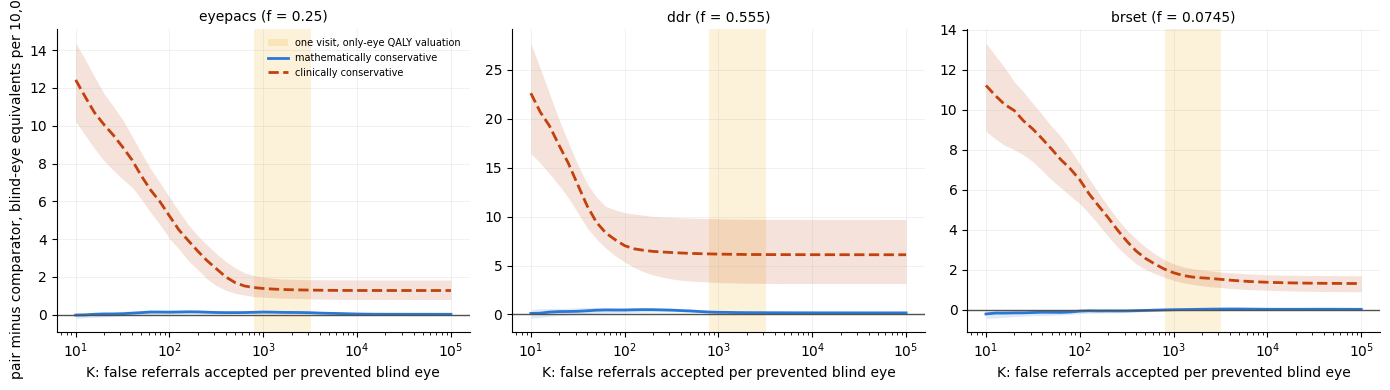

,population,bound,matched_volume_blind_eyes_per_10k,breakeven_K,tuned_QALY_per_10k_at_0.0025
0,eyepacs,mathematically conservative,+0.128 (+0.075 to +0.161),13 (below 10 to 74),+0.441 (+0.278 to +0.555)
1,eyepacs,clinically conservative,+6.907 (+5.386 to +8.462),below 10 (below 10 to below 10),+4.361 (+2.906 to +6.197)
2,ddr,mathematically conservative,+0.218 (+0.085 to +0.285),below 10 (below 10 to 31),+0.668 (+0.413 to +0.859)
3,ddr,clinically conservative,+10.915 (+6.045 to +15.916),below 10 (below 10 to below 10),+19.750 (+10.371 to +31.348)
4,brset,mathematically conservative,-0.087 (-0.183 to -0.016),"1,332 (537 to above 100,000)",-0.004 (-0.142 to +0.120)
5,brset,clinically conservative,+9.617 (+7.276 to +11.959),below 10 (below 10 to below 10),+5.441 (+4.280 to +6.837)


In [7]:
BOUNDS = {"mathematically conservative": ("better", "lit_central", "#2a78d6", "-"), "clinically conservative": ("deployed", "allblind", "#c2410c", "--")}
fig, ax = plt.subplots(1, len(RES), figsize=(14, 4))
for x, (name, r) in zip(np.atleast_1d(ax), RES.items()):
    x.axvspan(800, 3200, color="#eda100", alpha=0.15, lw=0, label="one visit, only-eye QALY valuation")
    for lab, (c, h, col, ls) in BOUNDS.items():
        tk = r[c]["tuned_k"][h]; x.fill_between(KS, np.percentile(tk[1:], 2.5, 0), np.percentile(tk[1:], 97.5, 0), color=col, alpha=0.15, lw=0)
        x.plot(KS, tk[0], color=col, lw=2, ls=ls, label=lab)
    x.axhline(0, color="#52514e", lw=1); x.set_xscale("log"); x.set_title(f"{name} (f = {r['f']})", fontsize=10)
    x.set_xlabel("K: false referrals accepted per prevented blind eye"); x.grid(alpha=0.25, lw=0.5); [x.spines[s].set_visible(False) for s in ("top", "right")]
np.atleast_1d(ax)[0].set_ylabel("pair minus comparator, blind-eye equivalents per 10,000"); np.atleast_1d(ax)[0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(f"{FIGS}/bounds_tuned_vs_K_v2.png", dpi=200); plt.show()
summ = []
for name, r in RES.items():
    for lab, (c, h, _, _) in BOUNDS.items():
        b = BE[(BE.population == name) & (BE.comparator == c) & (BE.harm == HARMS[h])].iloc[0]
        pm, lm, hm = ci(r[c]["matched"][h]); q = r[c]["tuned_q"][h]; pq, lq, hq = ci(q[:, 1])
        summ.append({"population": name, "bound": lab, "matched_volume_blind_eyes_per_10k": f"{pm:+.3f} ({lm:+.3f} to {hm:+.3f})", "breakeven_K": f"{b.breakeven_K} ({b.ci})",
                     f"tuned_QALY_per_10k_at_{LAM_ANCHOR}": f"{pq:+.3f} ({lq:+.3f} to {hq:+.3f})"})
SUMM = pd.DataFrame(summ); SUMM.to_csv(f"{RESULTS}/bounds_summary_v2.csv", index=False); display(SUMM)

## 7. Union at each model's own threshold, against both comparators
Refer every eye either model flags at f, per 10,000 eyes. Reported for each comparator:
- blind eyes avoided;
- extra false referrals;
- false referrals per blind eye avoided (the union pays when your K exceeds this).

In [8]:
rows = []
for name, r in RES.items():
    for c in CMP:
        fp = r[c]["union_fp"]; sv = r[c]["union_sev"]
        for h in ("lit_central", "allblind"):
            ev = r[c]["union_ev"][h]; row = {"population": name, "comparator": c, "harm": HARMS[h]}
            row["blind_eyes_avoided"], row["lo"], row["hi"] = ci(ev); row["severe_eyes_avoided"] = ci(sv)[0]; row["extra_false_referrals"] = ci(fp)[0]
            row["false_referrals_per_blind_eye_avoided"] = float(fp[0] / ev[0]) if ev[0] > 0 else float("nan")
            for lam in LAM_PTS:
                p, lo, hi = ci(ev * QPE - lam * fp); row[f"net_QALY_at_{lam}"] = f"{p:+.3f} ({lo:+.3f} to {hi:+.3f})"
            rows.append(row)
U = pd.DataFrame(rows); U.to_csv(f"{RESULTS}/bounds_D_union_v2.csv", index=False); display(U.round(3))

,population,comparator,harm,blind_eyes_avoided,lo,hi,severe_eyes_avoided,extra_false_referrals,false_referrals_per_blind_eye_avoided,net_QALY_at_0.001,net_QALY_at_0.0025,net_QALY_at_0.004
0,eyepacs,better,literature harm (central),0.386,0.316,0.455,10.092,599.270,1551.723,+0.640 (+0.415 to +0.865),-0.258 (-0.488 to -0.029),-1.157 (-1.399 to -0.913)
1,eyepacs,better,every missed severe eye blinds,10.537,7.836,12.604,10.092,599.270,56.874,+33.224 (+24.564 to +39.860),+32.325 (+23.683 to +38.964),+31.426 (+22.801 to +38.068)
2,eyepacs,deployed,literature harm (central),0.511,0.430,0.606,13.878,585.503,1146.308,+1.054 (+0.793 to +1.365),+0.176 (-0.088 to +0.499),-0.702 (-0.967 to -0.374)
3,eyepacs,deployed,every missed severe eye blinds,14.353,11.455,17.278,13.878,585.503,40.794,+45.487 (+36.175 to +54.866),+44.609 (+35.272 to +53.971),+43.730 (+34.366 to +53.076)
4,ddr,better,literature harm (central),0.896,0.564,1.253,14.843,638.276,712.456,+2.238 (+1.151 to +3.453),+1.280 (+0.082 to +2.611),+0.323 (-0.984 to +1.726)
5,ddr,better,every missed severe eye blinds,15.622,8.670,23.346,14.843,638.276,40.857,+49.509 (+27.067 to +74.205),+48.551 (+25.946 to +73.287),+47.594 (+25.012 to +72.424)
6,ddr,deployed,literature harm (central),1.220,0.775,1.742,21.762,635.681,520.997,+3.281 (+1.790 to +4.994),+2.327 (+0.749 to +4.136),+1.374 (-0.310 to +3.279)
7,ddr,deployed,every missed severe eye blinds,22.527,13.140,33.309,21.762,635.681,28.218,+71.677 (+41.445 to +106.304),+70.724 (+40.341 to +105.382),+69.770 (+39.283 to +104.483)
8,brset,better,literature harm (central),0.486,0.375,0.589,10.489,207.111,426.146,+1.353 (+0.996 to +1.687),+1.042 (+0.687 to +1.382),+0.732 (+0.371 to +1.070)
9,brset,better,every missed severe eye blinds,10.563,8.186,12.764,10.489,207.111,19.607,+33.701 (+26.068 to +40.763),+33.390 (+25.756 to +40.447),+33.079 (+25.443 to +40.130)


## 8. Write the results record

In [9]:
REC = {"status": "secondary, post hoc; companion to notebook 18; not specified in a dated lock", "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
       "comparators": {"better": "lower of the two members' costs, chosen per resample", "deployed": "average of the two members' costs (each equally likely to be deployed)"},
       "harm_models": {"literature": "notebook 18 values", "allblind": "each missed grade 3 or 4 eye counts as one blind eye; grade 2 at literature high (0.003)"},
       "bounds": {"mathematically_conservative": "better member, literature central", "clinically_conservative": "deployed model, every missed severe eye blinds"},
       "K_grid": [float(KS[0]), float(KS[-1]), len(KS)], "qaly_per_blind_eye_only_eye": QPE, "visit_qaly_points": LAM_PTS,
       "bootstrap": {"resamples": B, "seed": SEED}, "populations": {n: {"eyes": r["n"], "groups": r["groups"], "f": r["f"]} for n, r in RES.items()},
       "A_matched": A.drop(columns="cell").to_dict("records"), "B_breakeven": BE.drop(columns="cell").to_dict("records"), "summary": SUMM.to_dict("records"), "D_union": U.to_dict("records"), "input_sha256": HASHES}
with open(OUT_JSON, "w") as fh: json.dump(REC, fh, indent=1, default=float)
print("written", OUT_JSON)

written /content/drive/MyDrive/stochastic_orthogonality/data/dr_ensemble_v2/04_results/literature_weighted_bounds_v2.json
